In [1]:
# Ranking System Constants

# Rank Names
RANKS = {
    'BEGINNER': 'Beginner',
    'POKEBALL': 'Pokeball',
    'GREATBALL': 'Greatball',
    'ULTRABALL': 'Ultraball',
    'MASTERBALL': 'Masterball'
}

# Points required for each rank
RANK_THRESHOLDS = {
    'BEGINNER_1': 0,
    'BEGINNER_2': 20,
    'BEGINNER_3': 50,
    'BEGINNER_4': 95,
    'POKEBALL_1': 145,
    'POKEBALL_2': 195,
    'POKEBALL_3': 245,
    'POKEBALL_4': 300,
    'GREATBALL_1': 355,
    'GREATBALL_2': 420,
    'GREATBALL_3': 490,
    'GREATBALL_4': 600,
    'ULTRABALL_1': 710,
    'ULTRABALL_2': 860,
    'ULTRABALL_3': 1010,
    'ULTRABALL_4': 1225,
    'MASTERBALL': 1450
}

# Points gained/lost per match
POINTS_WIN = 10
POINTS_LOSS = {
    'BEGINNER': 0,
    'POKEBALL': 5,
    'GREATBALL': 5,
    'ULTRABALL': 7,
    'MASTERBALL': 10
}

# Consecutive win bonus settings
CONSECUTIVE_WIN_BONUS = 3
MAX_CONSECUTIVE_WIN_BONUS = 12
MAX_CONSECUTIVE_WINS_FOR_BONUS = 4  # This will give max bonus of 12 (3 * 4)

# Rank progression
RANK_PROGRESSION = [
    'BEGINNER_1', 'BEGINNER_2', 'BEGINNER_3', 'BEGINNER_4',
    'POKEBALL_1', 'POKEBALL_2', 'POKEBALL_3', 'POKEBALL_4',
    'GREATBALL_1', 'GREATBALL_2', 'GREATBALL_3', 'GREATBALL_4',
    'ULTRABALL_1', 'ULTRABALL_2', 'ULTRABALL_3', 'ULTRABALL_4',
    'MASTERBALL'
] 

In [2]:
# Simulation settings
import numpy as np

# Generate 100 match results (1 for win, 0 for loss)
#np.random.seed(42)  # For reproducibility
match_results = np.random.binomial(1, 0.5, 500) 

match_results

array([0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 0,
       1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0,
       0, 1, 0, 1, 1, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 1,
       1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 0,
       1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0,
       1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0, 1, 0,
       0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0,
       0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1,
       1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1,

In [3]:
def calculate_rank_progression(match_results):
    points = 0
    current_rank = 'BEGINNER_1'
    consecutive_wins = 0
    rank_history = []
    points_history = []
    
    for result in match_results:
        # Calculate points for this match
        if result == 1:  # Win
            points += POINTS_WIN
            consecutive_wins += 1
            
            # Apply consecutive win bonus if applicable
            if current_rank in RANK_PROGRESSION[:12]:  # Only for ranks up to GREATBALL_4
                bonus = min(consecutive_wins * CONSECUTIVE_WIN_BONUS, MAX_CONSECUTIVE_WIN_BONUS)
                points += bonus
        else:  # Loss
            consecutive_wins = 0
            rank_category = current_rank.split('_')[0]
            points -= POINTS_LOSS[rank_category]
            points = max(0, points)  # Points can't go below 0
        
        # Update rank based on points
        for rank in reversed(RANK_PROGRESSION):
            if points >= RANK_THRESHOLDS[rank]:
                current_rank = rank
                break
        
        rank_history.append(current_rank)
        points_history.append(points)
    
    return {
        'final_points': points,
        'final_rank': current_rank,
        'wins': sum(match_results),
        'losses': len(match_results) - sum(match_results),
        'rank_history': rank_history,
        'points_history': points_history
    }

In [4]:
# Calculate and print results
results = calculate_rank_progression(match_results)
print(f"Final Points: {results['final_points']}")
print(f"Final Rank: {results['final_rank']}")
print(f"Total Wins: {results['wins']}")
print(f"Total Losses: {results['losses']}")
print("\nRank Progression:")
for i, (rank, points) in enumerate(zip(results['rank_history'], results['points_history'])):
    if i == 0 or rank != results['rank_history'][i-1]:
        print(f"Match {i+1}: {rank} (Points: {points})") 

Final Points: 1305
Final Rank: ULTRABALL_4
Total Wins: 249
Total Losses: 251

Rank Progression:
Match 1: BEGINNER_1 (Points: 0)
Match 4: BEGINNER_2 (Points: 26)
Match 6: BEGINNER_3 (Points: 61)
Match 15: BEGINNER_4 (Points: 100)
Match 25: POKEBALL_1 (Points: 148)
Match 28: POKEBALL_2 (Points: 214)
Match 33: POKEBALL_3 (Points: 246)
Match 42: POKEBALL_4 (Points: 303)
Match 43: POKEBALL_3 (Points: 298)
Match 45: POKEBALL_4 (Points: 306)
Match 48: GREATBALL_1 (Points: 363)
Match 59: GREATBALL_2 (Points: 422)
Match 60: GREATBALL_1 (Points: 417)
Match 61: GREATBALL_2 (Points: 430)
Match 87: GREATBALL_3 (Points: 492)
Match 88: GREATBALL_2 (Points: 487)
Match 90: GREATBALL_3 (Points: 495)
Match 111: GREATBALL_4 (Points: 606)
Match 125: ULTRABALL_1 (Points: 716)
Match 148: GREATBALL_4 (Points: 708)
Match 158: ULTRABALL_1 (Points: 721)
Match 160: GREATBALL_4 (Points: 707)
Match 161: ULTRABALL_1 (Points: 720)
Match 250: ULTRABALL_2 (Points: 862)
Match 251: ULTRABALL_1 (Points: 855)
Match 252: UL

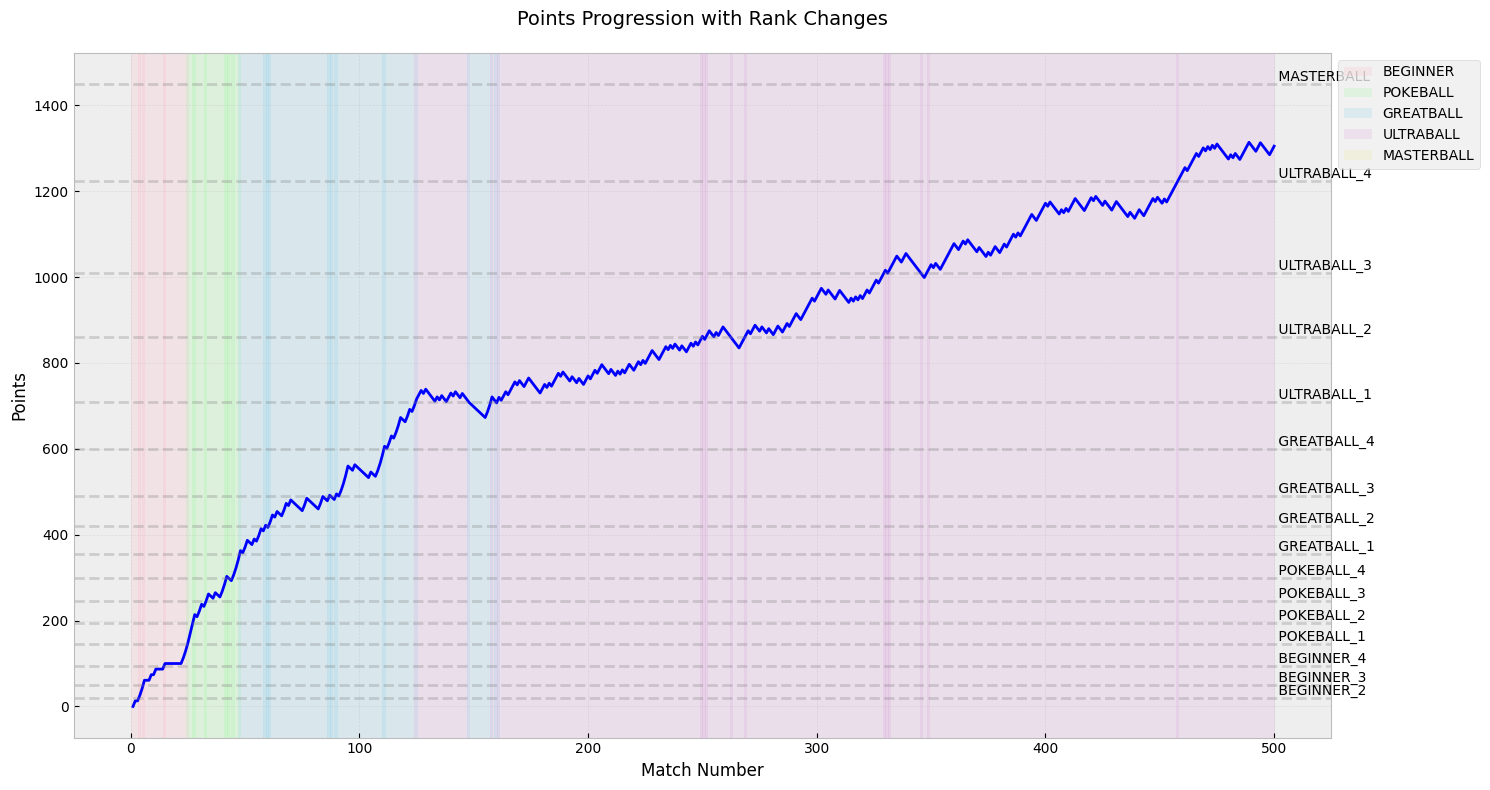

In [5]:
# Create visualization
import matplotlib.pyplot as plt
plt.style.use('bmh')
fig, ax = plt.subplots(figsize=(15, 8))

# Plot points progression
matches = range(1, len(results['points_history']) + 1)
ax.plot(matches, results['points_history'], 'b-', label='Points', linewidth=2)

# Find rank change points
rank_changes = []
for i in range(1, len(results['rank_history'])):
    if results['rank_history'][i] != results['rank_history'][i-1]:
        rank_changes.append((i+1, results['points_history'][i], results['rank_history'][i]))

# Color regions for different ranks
colors = {
    'BEGINNER': '#FFB6C1',  # Light pink
    'POKEBALL': '#98FB98',  # Light green
    'GREATBALL': '#87CEEB',  # Sky blue
    'ULTRABALL': '#DDA0DD',  # Plum
    'MASTERBALL': '#F0E68C'   # Khaki
}

# Add colored regions and rank change markers
current_rank = results['rank_history'][0]
start_idx = 0
for i, rank in enumerate(results['rank_history']):
    if rank != current_rank or i == len(results['rank_history'])-1:
        rank_category = current_rank.split('_')[0]
        ax.axvspan(start_idx, i+1, alpha=0.2, color=colors[rank_category])
        current_rank = rank
        start_idx = i


# Add rank threshold lines
for rank, threshold in RANK_THRESHOLDS.items():
    if threshold > 0:  # Skip BEGINNER_1 (0 points)
        ax.axhline(y=threshold, color='gray', linestyle='--', alpha=0.3)
        ax.text(len(matches), threshold, f' {rank}', verticalalignment='bottom')

# Customize the plot
ax.set_title('Points Progression with Rank Changes', fontsize=14, pad=20)
ax.set_xlabel('Match Number', fontsize=12)
ax.set_ylabel('Points', fontsize=12)
ax.grid(True, alpha=0.3)

# Add legend for rank colors
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=color, alpha=0.2, label=rank) 
                  for rank, color in colors.items()]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show() 

Running 10000 simulations with 2000 games each...


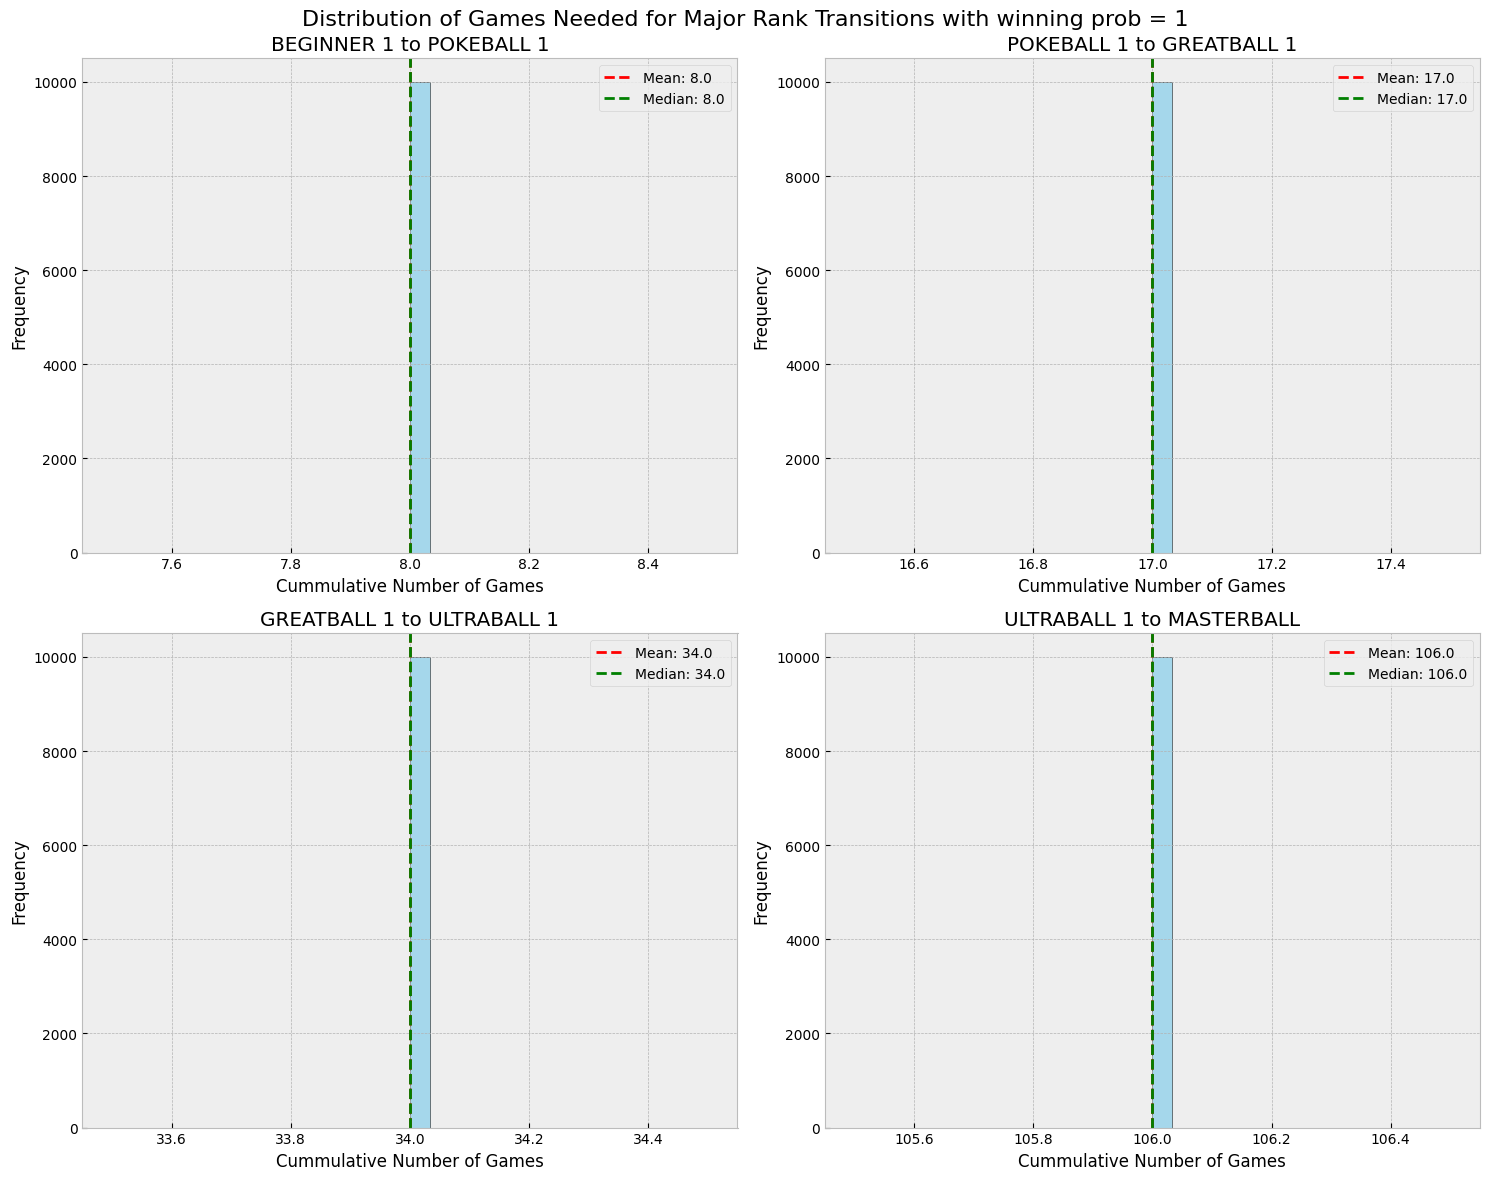

In [19]:
def run_single_simulation(n_games, prob = 0.5):
    """Run a single simulation of n_games and return rank progression data."""
    match_results = np.random.binomial(1, prob, n_games)
    results = calculate_rank_progression(match_results)
    return results

def get_major_rank_transitions(rank_history):
    """Get the match numbers for major rank transitions."""
    transitions = {
        'BEGINNER_1_to_POKEBALL_1': None,
        'POKEBALL_1_to_GREATBALL_1': None,
        'GREATBALL_1_to_ULTRABALL_1': None,
        'ULTRABALL_1_to_MASTERBALL': None
    }
    
    for i, rank in enumerate(rank_history):
        if rank == 'POKEBALL_1' and transitions['BEGINNER_1_to_POKEBALL_1'] is None:
            transitions['BEGINNER_1_to_POKEBALL_1'] = i + 1
        elif rank == 'GREATBALL_1' and transitions['POKEBALL_1_to_GREATBALL_1'] is None:
            transitions['POKEBALL_1_to_GREATBALL_1'] = i + 1
        elif rank == 'ULTRABALL_1' and transitions['GREATBALL_1_to_ULTRABALL_1'] is None:
            transitions['GREATBALL_1_to_ULTRABALL_1'] = i + 1
        elif rank == 'MASTERBALL' and transitions['ULTRABALL_1_to_MASTERBALL'] is None:
            transitions['ULTRABALL_1_to_MASTERBALL'] = i + 1
    
    return transitions

def run_multiple_simulations(n_simulations, n_games, prob = 0.5):
    """Run multiple simulations and collect rank transition data."""
    transition_data = {
        'BEGINNER_1_to_POKEBALL_1': [],
        'POKEBALL_1_to_GREATBALL_1': [],
        'GREATBALL_1_to_ULTRABALL_1': [],
        'ULTRABALL_1_to_MASTERBALL': []
    }
    
    for _ in range(n_simulations):
        results = run_single_simulation(n_games, prob)
        transitions = get_major_rank_transitions(results['rank_history'])
        
        for key in transition_data:
            if transitions[key] is not None:
                transition_data[key].append(transitions[key])
    
    return transition_data

def plot_transition_distributions(transition_data, prob = 0.5):
    """Plot distributions of games needed for each major rank transition."""
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    fig.suptitle('Distribution of Games Needed for Major Rank Transitions with winning prob = '+str(prob), fontsize=16)
    
    axes = axes.flatten()
    for idx, (transition, data) in enumerate(transition_data.items()):
        if data:  # Only plot if we have data
            ax = axes[idx]
            ax.hist(data, bins=30, alpha=0.7, color='skyblue', edgecolor='black')
            ax.set_title(transition.replace('_', ' '))
            ax.set_xlabel('Cummulative Number of Games')
            ax.set_ylabel('Frequency')
            
            # Add mean and median lines
            mean_games = np.mean(data)
            median_games = np.median(data)
            ax.axvline(mean_games, color='red', linestyle='--', label=f'Mean: {mean_games:.1f}')
            ax.axvline(median_games, color='green', linestyle='--', label=f'Median: {median_games:.1f}')
            ax.legend()
    
    plt.tight_layout()
    plt.show()

# Run simulations and plot distributions
n_simulations = 10000  # Number of simulations
n_games = 2000       # Maximum number of games per simulation
prob = 1
print(f"Running {n_simulations} simulations with {n_games} games each...")
transition_data = run_multiple_simulations(n_simulations, n_games, prob)
'''
# Print summary statistics
print("\nSummary Statistics for Rank Transitions:")
for transition, data in transition_data.items():
    if data:
        print(f"\n{transition.replace('_', ' ')}:")
        print(f"Mean games needed: {np.mean(data):.1f}")
        print(f"Median games needed: {np.median(data):.1f}")
        print(f"Min games needed: {min(data)}")
        print(f"Max games needed: {max(data)}")
        print(f"Number of successful transitions: {len(data)}")
        print(f"Success rate: {(len(data)/n_simulations)*100:.1f}%")
'''
# Plot the distributions
plot_transition_distributions(transition_data, prob) 